## Cover art (final): iris of the functional map, dark version

Builds the cover submitted to *Neuron*, and only that version. Each point is **one recorded neuron, shown as its own two-photon max-projection image** (tiles from `cover_art.ipynb`: ~30 µm crop around the ROI, inverted, neighbours masked out). Neurons are arranged as an iris:

- **Angle:** each neuron's angle around the ring formed by the clusters in the UMAP (Figure S15B), rank-ordered within its cell type, so neighbours on the iris have similar coding.
- **Radius:** cell type. Vip at the pupil edge, excitatory in the middle, Sst at the rim.
- **Colour:** functional cluster, in the cluster-type palette of Figure S15B, except cluster 6 (novelty suppressed) is brown instead of green, because Cell Press does not allow red and green together on covers.
- **Cells:** every clustered neuron with a sharp tile, except cluster 1 (non-coding) and the far UMAP outliers (x ≥ 16), as in S15B. Each neuron appears exactly once.

**Neuron cover specs:** ~9 × 11.5 in (final trim 8⅜ × 10⅞ in) at ≥ 300 dpi → 2700 × 3450 px; TIF (LZW); top 17% left clear for the masthead; no text in the art.

**Outputs** (`Final Figures/platform_paper_figures/cover_art/final/`):
- `cover_neuron_iris.tif` — the submission file
- `cover_neuron_iris_lowres.jpg` — low-resolution image for the cover PDF (≤ 1 MB)
- `cover_neuron_iris_layout.csv` — which neuron is where (cell_specimen_id, cell type, cluster, colour, position, size)

Description, legend and AI statement: `cover_art/final/cover_art_description.md`. Code: `cover_layout.py` (arrangement), `cover_render.py` (compositing).
The earlier versions (pie iris, light backgrounds) are in `cover_art/designs/misc/`; the notebook that made them is `archive/notebook_backups/cover_designs_2026-11-08_before_final.ipynb`.

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import visual_behavior.data_access.loading as loading

import cover_layout as L   # same folder as this notebook
import cover_render as R

%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'cover_art')
tile_dir = os.path.join(save_dir, 'cell_tiles_isolated')            # made by cover_art.ipynb
tile_manifest = os.path.join(tile_dir, 'tile_manifest_crisp.csv')   # tiles that passed the sharpness filter
out_dir = os.path.join(save_dir, 'final')
os.makedirs(out_dir, exist_ok=True)
NAME = 'cover_neuron_iris'
LOWRES_W = 900                                                      # px, for the cover PDF

## Data (same files as Figure 5 / S15B)

In [11]:
data_dir = loading.get_clustering_results_dir()
n_clusters = 14
cluster_meta = pd.read_hdf(os.path.join(data_dir, f'cluster_metadata_{n_clusters}_clusters.h5'), key='df')
umap_df = pd.read_hdf(os.path.join(data_dir, 'umap_results_df.h5'), key='df')

# one table of clustered cells: UMAP position, cluster, cell type (read by cover_layout.load_cells)
cluster_csv = os.path.join(out_dir, 'umap_cells.csv')
umap_df[['x', 'y']].join(cluster_meta[['cluster_id', 'cell_type']]).to_csv(cluster_csv)
print(len(cluster_meta), 'clustered cells;', len(pd.read_csv(tile_manifest)), 'sharp tiles')

3901 clustered cells; 3762 sharp tiles


## Layout and render

In [12]:
cells = L.load_cells(cluster_csv, tile_manifest, drop_clusters=(1,))   # cluster 1 (non-coding) left out, as in S15B
cells = cells[cells.x < 16]                                            # far UMAP outliers left out, as in S15B
layout = L.umap_iris(cells)

tif = os.path.join(out_dir, f'{NAME}.tif')
R.render(layout, tile_dir, tif, mode='dark')
im = Image.open(tif)
im.convert('RGB').resize((LOWRES_W, round(LOWRES_W * im.height / im.width)), Image.LANCZOS).save(
    os.path.join(out_dir, f'{NAME}_lowres.jpg'), quality=90, dpi=(72, 72))
keep = ['cell_specimen_id', 'cell_type', 'cluster_id', 'color', 'X', 'Y', 'size', 'filename']
layout[keep].to_csv(os.path.join(out_dir, f'{NAME}_layout.csv'), index=False)
print('neurons per cell type:', layout.cell_type.value_counts().to_dict(), '| total', len(layout))

neurons per cell type: {'Excitatory': 2326, 'Vip Inhibitory': 336, 'Sst Inhibitory': 183} | total 2845


## Checks against the Neuron cover specs

In [13]:
im = Image.open(tif)
out = ((layout.X - layout['size'] / 2 < 94) | (layout.X + layout['size'] / 2 > L.W - 94) |
       (layout.Y - layout['size'] / 2 < L.TOP) | (layout.Y + layout['size'] / 2 > L.H - 94)).sum()
print(f'{NAME}.tif: {im.size[0]} x {im.size[1]} px = {im.size[0] / 300:.2f} x {im.size[1] / 300:.2f} in at '
      f'{im.info.get("dpi")} dpi, {os.path.getsize(tif) / 1e6:.1f} MB (limit 100 MB)')
print(f'{len(layout)} tiles, {layout.cell_specimen_id.nunique()} unique neurons, '
      f'{out} outside the trim (94 px per edge) or in the masthead band')
print('low-res jpg:', round(os.path.getsize(os.path.join(out_dir, f"{NAME}_lowres.jpg")) / 1e3), 'kB')

cover_neuron_iris.tif: 2700 x 3450 px = 9.00 x 11.50 in at (300.0, 300.0) dpi, 5.3 MB (limit 100 MB)
2845 tiles, 2845 unique neurons, 0 outside the trim (94 px per edge) or in the masthead band
low-res jpg: 217 kB


Text(0.5, 1.0, 'cover_neuron_iris (low-res preview)')

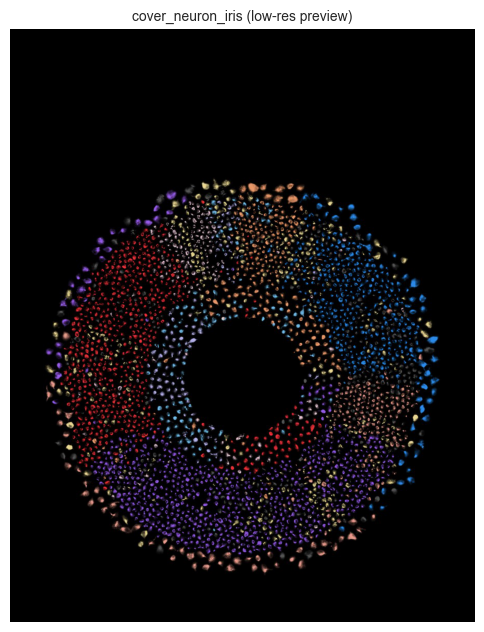

In [14]:
fig, ax = plt.subplots(figsize=(6, 7.7))
ax.imshow(Image.open(os.path.join(out_dir, f'{NAME}_lowres.jpg'))); ax.axis('off')
ax.set_title(NAME + ' (low-res preview)', fontsize=10)